IMPORTING THE LIBRARIES

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score


LOADING DATASET AND DATA SUMMARY 

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


DATA SUMMARY..
MEAN..
income_annum                5.059124e+06
loan_amount                 1.513345e+07
cibil_score                 5.999361e+02
residential_assets_value    7.472617e+06
commercial_assets_value     4.973155e+06
luxury_assets_value         1.512631e+07
bank_asset_value            4.976692e+06
dtype: float64

MEDIAN VALUES..
income_annum                 5100000.0
loan_amount                 14500000.0
cibil_score                      600.0
residential_assets_value     5600000.0
commercial_assets_value      3700000.0
luxury_assets_value         14600000.0
bank_asset_value             4600000.0
dtype: float64

COVARIANCE..
                          income_annum   loan_amount   cibil_score  \
income_annum              7.878350e+12  2.354222e+13 -1.114830e+07   
loan_amount               2.354222e+13  8.178241e+13 -2.656321e+07   
cibil_score              -1.114830e+07 -2.656321e+07  2.973224e+04   
residential_assets_value  1.162533e+13  3.497100e+13 -2.236879e+07   
commerc

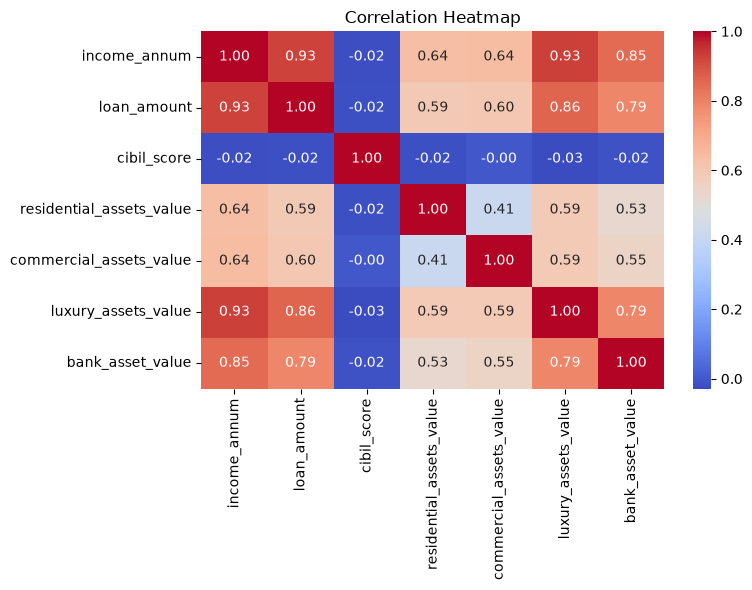

In [37]:
df=pd.read_csv('data/loan_approval_dataset.csv')
display(df.head())
df.columns=df.columns.str.strip() # To remove the extra spaces in the features.

print("DATA SUMMARY..")
numeric_columns=df[["income_annum",'loan_amount','cibil_score','residential_assets_value','commercial_assets_value','luxury_assets_value','bank_asset_value']]
print("MEAN..")
print(numeric_columns.mean())
print()
print("MEDIAN VALUES..")
print(numeric_columns.median())
print()
print("COVARIANCE..")
print(numeric_columns.cov())

# Correlation Heatmap 
plt.figure(figsize=(8,6))
sns.heatmap(numeric_columns.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


PREPROCESSING USING PIPELINES

In [ ]:
# Creating Pipelines for preprocessing  
numeric_transformer=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median")),
        ("scaler",StandardScaler())
    ]
)
categorical_transformer=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(drop="first",handle_unknown="ignore")) 
    ]
)
preprocessor=ColumnTransformer(
    transformers=[
        ("numeric",numeric_transformer,numeric_features),
        ("categorical",categorical_transformer,categorical_features)
    ]
)